In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

In [ ]:
from sklearn.naive_bayes import CategoricalNB
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [ ]:
df = pd.read_csv("/content/archive (1).zip")

In [ ]:
df

,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes
5,D6,Rain,Cool,Normal,Strong,No
6,D7,Overcast,Cool,Normal,Strong,Yes
7,D8,Sunny,Mild,High,Weak,No
8,D9,Sunny,Cool,Normal,Weak,Yes
9,D10,Rain,Mild,Normal,Weak,Yes


In [ ]:
df.tail()

,day,outlook,temp,humidity,wind,play
9,D10,Rain,Mild,Normal,Weak,Yes
10,D11,Sunny,Mild,Normal,Strong,Yes
11,D12,Overcast,Mild,High,Strong,Yes
12,D13,Overcast,Hot,Normal,Weak,Yes
13,D14,Rain,Mild,High,Strong,No


In [ ]:
df.head()

,day,outlook,temp,humidity,wind,play
0,D1,Sunny,Hot,High,Weak,No
1,D2,Sunny,Hot,High,Strong,No
2,D3,Overcast,Hot,High,Weak,Yes
3,D4,Rain,Mild,High,Weak,Yes
4,D5,Rain,Cool,Normal,Weak,Yes


In [ ]:
import pandas as pd
from sklearn.naive_bayes import CategoricalNB
from sklearn.preprocessing import LabelEncoder

In [ ]:
data = {
    'Outlook': ['Sunny', 'Sunny', 'Overcast', 'Rain', 'Rain',
                'Rain', 'Overcast', 'Sunny', 'Sunny', 'Rain',
                'Sunny', 'Overcast', 'Overcast', 'Rain'],

    'Temperature': ['Hot', 'Hot', 'Hot', 'Mild', 'Cool',
                    'Cool', 'Cool', 'Mild', 'Cool', 'Mild',
                    'Mild', 'Mild', 'Hot', 'Mild'],

    'Humidity': ['High', 'High', 'High', 'High', 'Normal',
                 'Normal', 'Normal', 'High', 'Normal', 'Normal',
                 'Normal', 'High', 'Normal', 'High'],

    'Wind': ['Weak', 'Strong', 'Weak', 'Weak', 'Weak',
             'Strong', 'Strong', 'Weak', 'Weak', 'Weak',
             'Strong', 'Strong', 'Weak', 'Strong'],

    'PlayTennis': ['No', 'No', 'Yes', 'Yes', 'Yes',
                   'No', 'Yes', 'No', 'Yes', 'Yes',
                   'Yes', 'Yes', 'Yes', 'No']
}

In [ ]:
df = pd.DataFrame(data)
df

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


In [ ]:
le = {}

df_enc = df.copy()

for col in df.columns:
    le[col] = LabelEncoder()
    df_enc[col] = le[col].fit_transform(df[col])

df_enc

,Outlook,Temperature,Humidity,Wind,PlayTennis
0,2,1,0,1,0
1,2,1,0,0,0
2,0,1,0,1,1
3,1,2,0,1,1
4,1,0,1,1,1
5,1,0,1,0,0
6,0,0,1,0,1
7,2,2,0,1,0
8,2,0,1,1,1
9,1,2,1,1,1


In [ ]:
X = df_enc[['Outlook', 'Temperature', 'Humidity', 'Wind']]
y = df_enc['PlayTennis']

model = CategoricalNB()
model.fit(X, y)

print("Model trained successfully!")

Model trained successfully!


In [ ]:
test = [['Sunny', 'Cool', 'High', 'Strong']]

In [ ]:
print("Prediction")

for t in test:
    row = [[
        le['Outlook'].transform([t[0]])[0],
        le['Temperature'].transform([t[1]])[0],
        le['Humidity'].transform([t[2]])[0],
        le['Wind'].transform([t[3]])[0]
    ]]

    pred = le['PlayTennis'].inverse_transform(model.predict(row))

    prob = model.predict_proba(row)[0]

    print("Input:", t)
    print("Result: Play Tennis ->", pred[0])
    print("P(No) =", round(prob[list(le['PlayTennis'].classes_).index('No')], 4))
    print("P(Yes) =", round(prob[list(le['PlayTennis'].classes_).index('Yes')], 4))

Prediction
Input: ['Sunny', 'Cool', 'High', 'Strong']
Result: Play Tennis -> No
P(No) = 0.7201
P(Yes) = 0.2799


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but CategoricalNB was fitted with feature names
  warnings.warn(


In [ ]:
from sklearn.metrics import accuracy_score

y_pred = model.predict(X)

print("Training Accuracy:", round(accuracy_score(y, y_pred) * 100, 2), "%")

Training Accuracy: 92.86 %


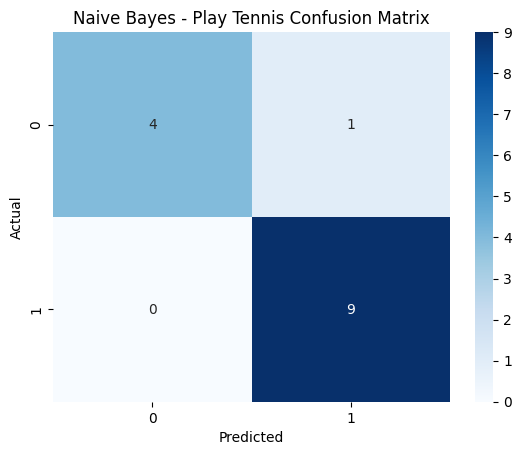

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.title("Naive Bayes - Play Tennis Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

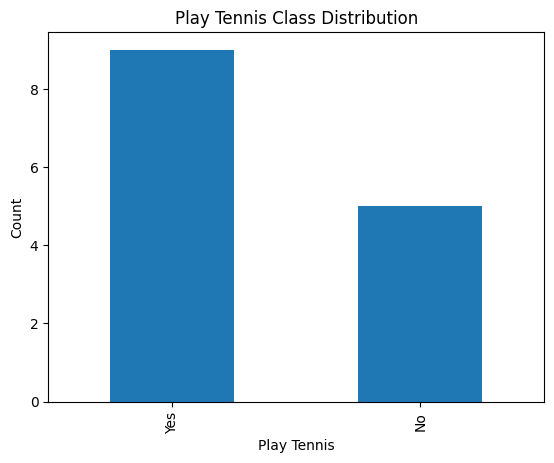

In [ ]:
df['PlayTennis'].value_counts().plot(kind='bar')

plt.title("Play Tennis Class Distribution")
plt.xlabel("Play Tennis")
plt.ylabel("Count")

plt.show()

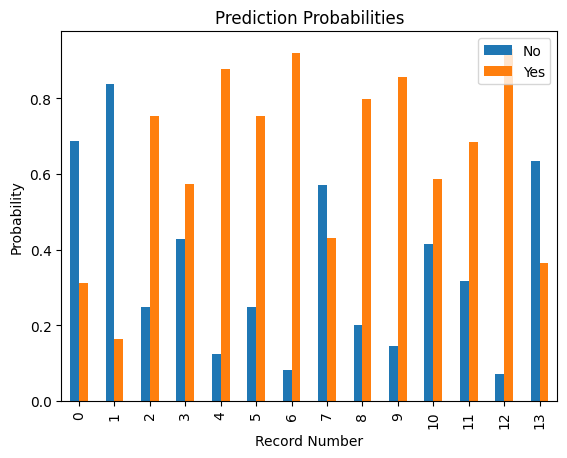

In [ ]:
prob_df = pd.DataFrame(
    model.predict_proba(X),
    columns=le['PlayTennis'].classes_
)

prob_df.plot(kind='bar')

plt.title("Prediction Probabilities")
plt.xlabel("Record Number")
plt.ylabel("Probability")

plt.show()

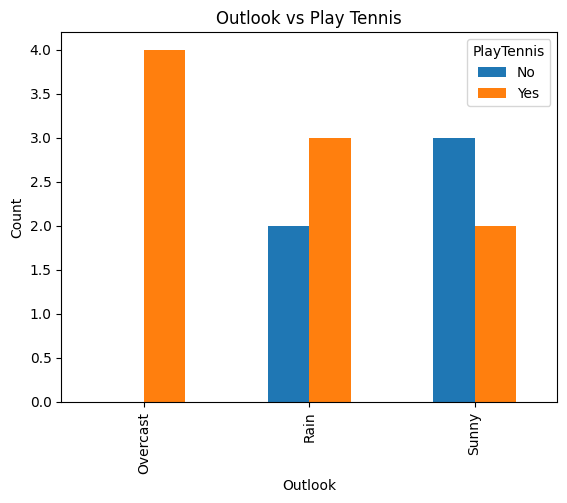

In [ ]:
pd.crosstab(df['Outlook'], df['PlayTennis']).plot(kind='bar')

plt.title("Outlook vs Play Tennis")
plt.xlabel("Outlook")
plt.ylabel("Count")

plt.show()

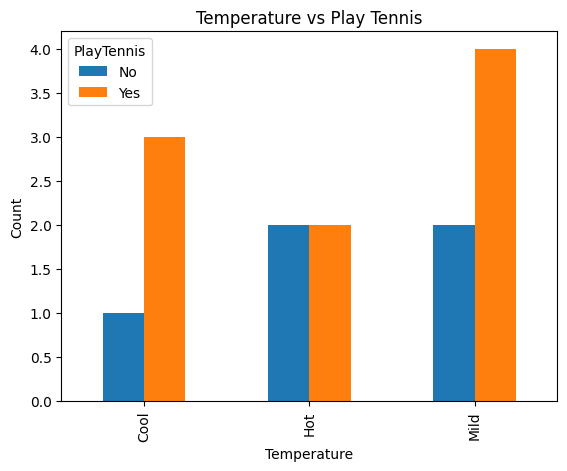

In [ ]:
pd.crosstab(df['Temperature'], df['PlayTennis']).plot(kind='bar')

plt.title("Temperature vs Play Tennis")
plt.xlabel("Temperature")
plt.ylabel("Count")

plt.show()

In [ ]:
print("Actual Values:")
print(le['PlayTennis'].inverse_transform(y))

print("\nPredicted Values:")
print(le['PlayTennis'].inverse_transform(y_pred))

Actual Values:
['No' 'No' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes'
 'No']

Predicted Values:
['No' 'No' 'Yes' 'Yes' 'Yes' 'Yes' 'Yes' 'No' 'Yes' 'Yes' 'Yes' 'Yes'
 'Yes' 'No']
